<!-- Navigation Bar HTML Structure -->
<!-- HEADER -->
  <header>
    <div class="logo"><a href="index.html" style="color: black;">Sara Sharifzadeh</a></div>
    <nav>
      <a href="work.html" style="color: black;">Work</a>
      <a href="about.html" style="color: black;">About Me</a>
      <a href="contact.html" style="color: black;">Contact</a>
    </nav>
  </header>



<!-- Navbar Styling (CSS) -->
<style>
header{position:fixed; inset:0 0 auto 0; z-index:1000;
      display:flex; align-items:center; justify-content:space-between;
      height:72px; padding:0 2.5%;
      background:rgba(255,255,255,0.75);
      backdrop-filter:blur(6px);
      border-bottom:2px solid var(--border) !important;
      transition:background .25s ease, box-shadow .25s ease;}


.logo{font-size:.95rem; font-weight:200}

.logo a{color:inherit; text-decoration:none}

nav{display:flex; gap:28px}

nav a{font-weight:200; text-decoration:none; color:var(--muted); position:relative; font-size:.95rem}

nav a:hover{color:var(--ink)}

nav a::after{content:""; position:absolute; left:0; bottom:-4px; height:1px; width:0; background:var(--ink); transition:width .25s ease}

nav a:hover::after{width:100%}
</style>

<br>

In [61]:
# import re
# #cleaning the Quarter with regex 
#     #currently "q1_22.csv" goal: q1
# #https://regex101.com

# pattern21 = '(\d\d\d\d.\w\w\w)'
# text = 'q12021.csv'

# ev21["Quarter"] = ev21["Quarter"].str.replace(pattern21, "", regex=True)
# ev21


# EV Charging Demand in California

**Quick Summary:** In this project I analyze EV Charging Infrastructure acrosss 50+ counties in California in 2021. My goal is to assess future charging needs as determined by EV demand, county populations, & tradeoffs of Public & DC fast charging.


**Tools:** `Python`, `SQL`, `NumPy`, `Pandas`, `SQLite`, `Plotly`, `Seaborn`

**Project Inspiration:** [EV Charging Economics 101, Catalyst](https://medium.com/catalyst-climate/ev-charging-economics-101-f932925beb78) - Darren Hau

### Context

In 2021, the Bipartisan group announced a [large investment in infrastructure](https://www.whitehouse.gov/briefing-room/statements-releases/2021/07/28/fact-sheet-historic-bipartisan-infrastructure-deal/) including $7.5 billion to build out a national network of EV Chargers. According to the [CA Energy Commission](https://www.energy.ca.gov/data-reports/energy-almanac/zero-emission-vehicle-and-infrastructure-statistics/new-zev-sales), new Zero-Emission Vehicle Sales in CA (2021) accounted for about 12% of all new cars sold, and in 2022 it was 18.8%.

CA needs to account for the new influx of EV's by developing a robust charging infrastructure in order to support consumer confidence and retention in sustainable transportation alternatives.


### EV Economics & Issues

A few major problems with charging networks today:

* **Most Public charging stations are inefficient & inconvenient:**
    * Level 1 (AC) charge from empty in an average of 11-20 hours
    * Level 2 (AC) charge from empty in an average of 3-8 hours
<br>
* **While major cities take up a larger share of EV sales, the national renting rate is at**
[55.5 percent](https://www.census.gov/quickfacts/fact/table/CA/HSG445221#HSG445221), **and they lack home charging opportunties:**
    * City dwellers typically do not have persnal home garages
    * Chargers built into apartment lots are rare & may be used inefficiently (left overnight, few slots)


### The Need for DC Fast 

This points to the need for public (DC) fast stations to offer convenient & accessible charging. According to [Edison Electric Insitute](https://www.eei.org/-/media/Project/EEI/Documents/Issues-and-Policy/Electric-Transportation/EV-Forecast--Infrastructure-Report.pdf) approximately 140,000 DC fast charging (DCFC) ports will be needed to accomodate US Roads in 2030.



In [196]:
# imports

import pandas as pd
import numpy as np
import os
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import plotly.figure_factory as ff
import plotly, geopandas, shapely
import plotly.graph_objects as go
import plotly.io as pio
import sqlite3
from pathlib import Path

pio.renderers

import shapely
import warnings
from shapely.errors import ShapelyDeprecationWarning
warnings.filterwarnings("ignore", category=ShapelyDeprecationWarning) 

import warnings
warnings.filterwarnings("ignore", "is_categorical_dtype")
warnings.filterwarnings("ignore", "use_inf_as_na")
# warnings.filterwarnings("ignore", "FutureWarning")



##  Datasets

### New EV Sales - CA Counties

Zero Emission Vehicles (ZEV) sales are updated on a quarterly basis by examining the DMV Vehicle Registration database for vehicles

* **citation:** California Energy Commission (2023). California Energy Commission Zero Emission Vehicle and Infrastructure Statistics. Data last updated [09/30/2023]. Retrieved [11/27/2023] from http://www.energy.ca.gov/zevstats

### EV Charging  Data - CA Counties
I got this dataset from California Energy Commission (CEC), which was obtained from the Alternative Fuels Data Center Station Locator (AFDC), managed by the National Renewable Energy Laboratory (NREL).

* `Public`: Charging data must be reported to the NREL by station operators or developers.

* `Private` :Charger counts are obtained from voluntary surveys issued by the CEC, which are sent to Electric Vehicle Service Providers (EVSP) & Non-EVSPs. Shared private chargers include: workplaces, multi-family housing, fleets, other non-public venues.

* **citation:** California Energy Commission (2023). Electric Vehicle Chargers in California. Data last updated [09/16/2023]. Retrieved [11/19/2023] from https://www.energy.ca.gov/zevstats


### FIPS
Every US state and county has an assigned ID regulated by the US Federal Government under the term FIPS (Federal Information Processing Standards) codes.

* `FIPS`: a state FIPS code (eg. 06 for California) with a county FIPS code of the state (eg. 059 for Orange county) and this new state-county FIPS code (06059) uniquely refers to the specified state and county.
* **citation:** https://github.com/kjhealy/fips-codes/blob/master/county_fips_master.csv


### CA County Population Estimates: 

* `population` per County - US Census data for estimates of CA County populations in the year 2021 to determine the "best" counties for EV charging by chargers per 100K people. 


*** 

# Exploratory Data Analysis (EDA) 
Data Cleaning & Exploration

### FIPS Data

In [216]:
# FIPS DATA 

fips = pd.read_csv("data/county_fips_master.csv")

#ENCODING ERROR
import chardet

with open('data/county_fips_master.csv', 'rb') as f:
    result = chardet.detect(f.read())

fips = pd.read_csv('data/county_fips_master.csv', encoding=result['encoding'])
CAfips = fips[fips['state_abbr']== 'CA']
CAfips = CAfips[["fips", "county_name"]]

CAfips["county_name"] = CAfips["county_name"].str.replace(" County", "")
CAfips.head()

,fips,county_name
187,6001,Alameda
188,6003,Alpine
189,6005,Amador
190,6007,Butte
191,6009,Calaveras


### Zero Emission Vehicle (ZEV) Sales Data in California

In [217]:
# Zero Emission Vehicle (ZEV) SALES DATA 

zev = pd.read_csv("data/zevsales.csv")
zev = zev.rename(columns={"Data Year":"year", "County":"county", "FUEL_TYPE":"fuel_type", "MAKE":"make", "MODEL": "model", "Number of Vehicles":"num_vehicles"})
print("dataset preview")
display(zev.head())

# Fuel Types that make up ZEV 
pd.DataFrame(zev["fuel_type"].unique()).rename(columns={0:"fuel_types"})


dataset preview


,year,county,fuel_type,make,model,num_vehicles
0,1998,Los Angeles,Electric,Ford,Ranger,1
1,1998,Orange,Electric,Ford,Ranger,1
2,1998,San Bernardino,Electric,Ford,Ranger,2
3,1998,San Mateo,Electric,Ford,Ranger,1
4,1999,Santa Barbara,Electric,Ford,Ranger,1


,fuel_types
0,Electric
1,Hydrogen
2,PHEV


In [218]:
# There are only 3 fuel types 
ev = zev[zev["fuel_type"]=="Electric"]
hydrogen = zev[zev["fuel_type"]!="Hydrogen"]
phev = zev[zev["fuel_type"]!="PHEV"]

In [219]:
# Number of ZEVs per Year -- any fuel type 
zev_per_year = zev.groupby(["year"]).sum("num_vehicles").reset_index()

# Number of ZEVs per Year, broken down by fuel type
zev_per_year_ft = zev.groupby(["year", "fuel_type"]).sum("num_vehicles").reset_index()

# 2021-2023 ZEVs
print("2021-2023 Number of ZEV vehicles per Fuel Type")
display(zev_per_year_ft.tail(9))


2021-2023 Number of ZEV vehicles per Fuel Type


,year,fuel_type,num_vehicles
44,2021,Electric,183933
45,2021,Hydrogen,3205
46,2021,PHEV,63141
47,2022,Electric,292496
48,2022,Hydrogen,2574
49,2022,PHEV,50748
50,2023,Electric,291649
51,2023,Hydrogen,2912
52,2023,PHEV,48327


Visualizing ZEV Sales Data by Fuel Type

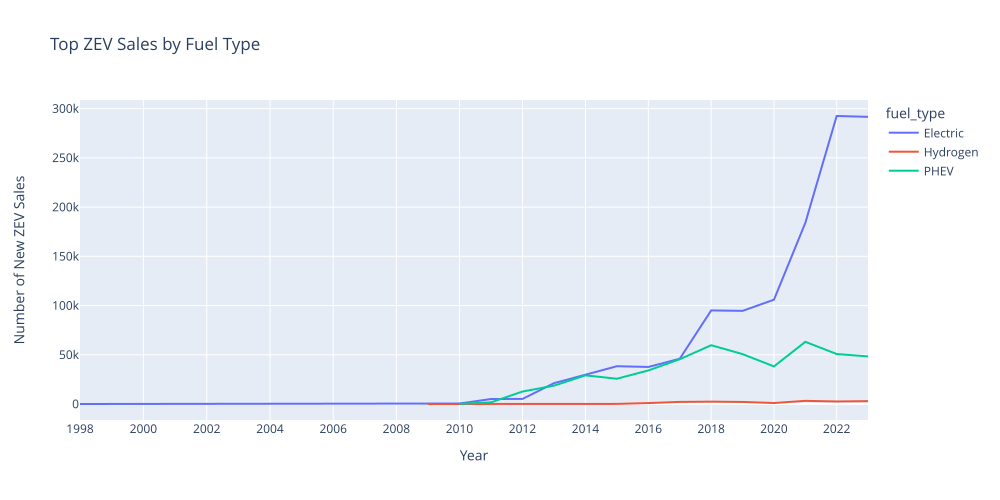

In [220]:
# vehicles_per_year_ft
fig = px.line(zev_per_year_ft, x="year", y="num_vehicles",
                color="fuel_type",
                labels={'year':'Year', 'num_vehicles':'Number of New ZEV Sales'},
                title="Top ZEV Sales by Fuel Type",
                log_x=True)

fig.update_layout(height=500, width=1000, showlegend=True)
fig.show(renderer="svg")


Takeaway: 
* Among Zero Emission Vehicles, Fully Electric Fuel Types are the most sought after. 
* Growth really picked up in 2020.

#### Diving Deeper into County Analysis

In [221]:
# number of zevs per county and year
print("Preview Number of ZEVs per county, year")
top_counties = zev.groupby(["county", "year"]).sum("num_vehicles").reset_index()
display(top_counties.head(5))
print("Record ZEV Sales per county, year")
display(top_counties.sort_values("num_vehicles", ascending=False).head(10))

Preview Number of ZEVs per county, year


,county,year,num_vehicles
0,Alameda,2009,5
1,Alameda,2010,13
2,Alameda,2011,452
3,Alameda,2012,1165
4,Alameda,2013,2943


Record ZEV Sales per county, year


,county,year,num_vehicles
249,Los Angeles,2023,96739
248,Los Angeles,2022,96090
247,Los Angeles,2021,67296
388,Orange,2022,43517
389,Orange,2023,42538
244,Los Angeles,2018,39657
246,Los Angeles,2020,38249
245,Los Angeles,2019,38219
387,Orange,2021,31917
598,Santa Clara,2023,30347


Narrowing down to Years 2020-2023

In [222]:
# 2020-2023 ZEV Sales
zev20to23 = zev[ (zev["year"]>=2020) & (zev["year"]<=2023) ]

# Top ZEV Sales Year 
top_year = zev20to23.groupby("year").sum("num_vehicles").sort_values("num_vehicles", ascending=False).reset_index()
print("Top ZEV Sales per Year from 2020 to 2023")
display(top_year)

# Narrowing Down to 2023 (todo -- reupload with new data)
top_counties23 = top_counties[top_counties["year"]==2023].groupby("county").max("num_vehicles").sort_values("num_vehicles", ascending=False).reset_index().iloc[0:5]#["county"].unique()
print("Top 5 Counties in 2023")
display(top_counties23)

bot_counties23 = top_counties[top_counties["year"]==2023].groupby("county").max("num_vehicles").sort_values("num_vehicles", ascending=True).reset_index().iloc[0:5]#["county"].unique()
print("Bottom 5 Counties in 2023")
bot_counties23


Top ZEV Sales per Year from 2020 to 2023


,year,num_vehicles
0,2022,345818
1,2023,342888
2,2021,250279
3,2020,145099


Top 5 Counties in 2023


,county,year,num_vehicles
0,Los Angeles,2023,96739
1,Orange,2023,42538
2,Santa Clara,2023,30347
3,San Diego,2023,29934
4,Alameda,2023,20437


Bottom 5 Counties in 2023


,county,year,num_vehicles
0,Modoc,2023,1
1,Sierra,2023,2
2,Alpine,2023,7
3,Lassen,2023,13
4,Trinity,2023,15


Takeaway: 
* Want to look deeper into Los Angeles, Orange, Santa Clara, San Diego, Alameda.

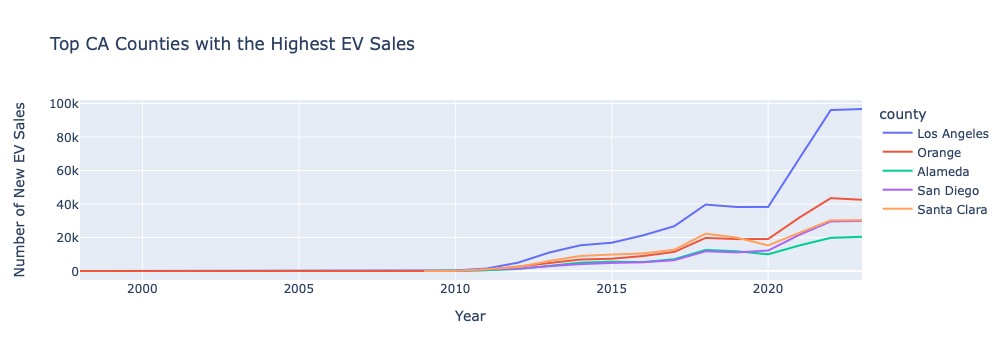

In [223]:
# Focusing on Los Angeles, Orange, Santa Clara, San Diego, Alameda.
major_counties = zev[ zev["county"].isin(["Los Angeles", "Orange", "Santa Clara", "San Diego", "Alameda"]) ]
# sum of vehicles per year
mc_v_per_year = major_counties.groupby(["year", "county"]).sum("num_vehicles").reset_index()

fig = px.line(mc_v_per_year, x="year", y="num_vehicles",
                color="county",
                labels={'year':'Year', 'num_vehicles':'Number of New EV Sales'},
                title="Top CA Counties with the Highest EV Sales",
                )

# fig.show(renderer="svg")
fig.show()

In [206]:
# # 2020 and 2023 
# mc_20to23 = major_counties[ (major_counties["year"]>=2020) & (major_counties["year"]<=2023)]
# mc_v_per_year20to23 = mc_20to23.groupby(["year", "county"]).sum("num_vehicles").reset_index()

# fig = px.line(mc_v_per_year20to23, x="year", y="num_vehicles",
#                 color="county",
#                 labels={'year':'Year', 'num_vehicles':'Number of New EV Sales'},
#                 title="Top CA Counties with the Highest EV Sales, 2020 to 2023",
#                 )

# fig.update_layout(
#     xaxis=dict(
#         tickmode='linear',
#         tick0=2020,     # The starting year of your data
#         dtick=1         # Forces a tick at every 1 whole unit (year)
#     )
# )

# fig.show(renderer="svg")
# # fig.show()

### California EV Charging Data (2021..)

In [225]:
files = Path("data/ev2021").glob("*.csv")

charging21 = pd.concat(
    [
        pd.read_csv(file).assign(Quarter=file.stem)
        for file in files
    ],
    ignore_index=True
)

print("original dataset, 4 quarters combined")
display(charging21.head(1))
# cleaning
print("renamed columns")
charging21.rename(columns={"County":"county", "Public Level 1":"public_l1", "Shared Private Level 1":"shared_private_l1",
                           "Public Level 2":"public_l2", "Shared Private Level 2":"shared_private_l2", "Public DC Fast":"public_dc_fast",
                           "Shared Private DC Fast":"shared_private_dc_fast", "Total":"total", "Quarter":"quarter"}, inplace=True)
# charging21.tail(3)
display(charging21.sort_values(["quarter", "county"]).head(3))

# Validate a County appears 4 times
print("Validate data is as expected, a county appears 4 times")
display((charging21 == "Yuba").sum().sum() == 4)
display(charging21[charging21["county"] == "Alameda"][["county", "quarter"]])



original dataset, 4 quarters combined


,County,Public Level 1,Shared Private Level 1,Public Level 2,Shared Private Level 2,Public DC Fast,Shared Private DC Fast,Total,Quarter
0,Alameda,6,70,1671,1583,332,35,3697,q4


renamed columns


,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter
180,Alameda,14,14,1519,1472,296,38,3353,q1
181,Alpine,0,0,14,1,0,0,15,q1
182,Amador,0,0,25,7,8,0,40,q1


Validate data is as expected, a county appears 4 times


True

,county,quarter
0,Alameda,q4
60,Alameda,q3
120,Alameda,q2
180,Alameda,q1


## Visual Exploration

#### Lets merge datasets to visually explore  Total EV Chargers per County with FIPS data

I need to map State & County Codes

In [270]:
# cleaning & mapping 
# ensure county names are type str
charging21["county"] = charging21["county"].astype(str)
CAfips["county_name"] = CAfips["county_name"].astype(str)
CAfips['fips'] = CAfips['fips'].astype('Int64') # prevent int converting to a float when nulls exist

# observe what returns NULL in an outer mapping:
#   1) an "Unknown" county in charging dataset
#   2) a "Total" row in chargning dataset
#  ---> safe to fill 0
mapped21 = charging21.merge(CAfips, left_on="county", right_on="county_name", how='outer')
display(mapped21[mapped21.isna().any(axis=1)])
mapped21 = mapped21.fillna(0)


mapped21.head()

,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter,fips,county_name
220,Unknown,0,0,0,14,0,0,14,q4,<NA>,NaN
221,Unknown,0,0,0,11,0,0,11,q3,<NA>,NaN
222,Unknown,0,0,0,11,0,0,11,q2,<NA>,NaN
223,Unknown,0,0,0,11,0,0,11,q1,<NA>,NaN
236,Total,228,401,28671,42565,6695,463,79023,q4,<NA>,NaN
237,Total,280,397,27734,40985,6144,632,76172,q3,<NA>,NaN
238,Total,301,350,27392,40050,5742,624,74459,q2,<NA>,NaN
239,Total,326,109,24880,39201,5404,559,70479,q1,<NA>,NaN


,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter,fips,county_name
0,Alameda,6,70,1671,1583,332,35,3697,q4,6001,Alameda
1,Alameda,14,66,1633,1554,315,43,3625,q3,6001,Alameda
2,Alameda,14,63,1633,1497,310,43,3560,q2,6001,Alameda
3,Alameda,14,14,1519,1472,296,38,3353,q1,6001,Alameda
4,Alpine,0,0,14,0,0,0,14,q4,6003,Alpine


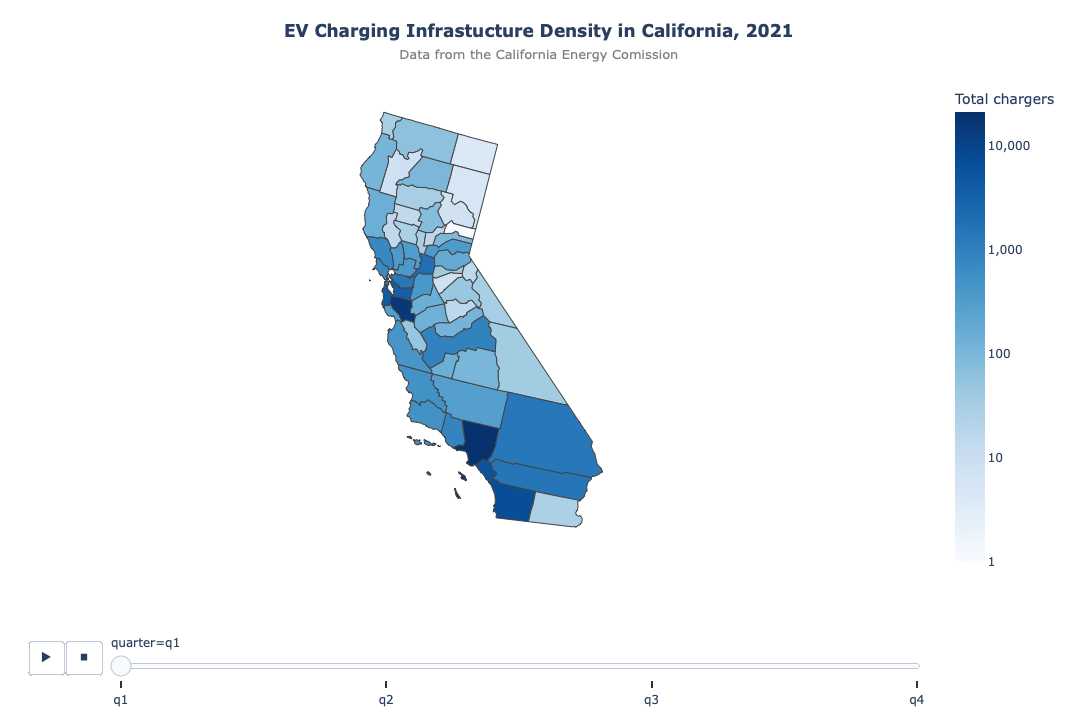

In [325]:
df=mapped21.copy()

df = df[~df["county"].isin(["Total", "Unknown"])].sort_values("quarter") # remove 'Uknown' & 'Total' County counts
df["fips"] = df["fips"].astype(str).str.zfill(5) # make any FIPS 0 a 5-digit str.
df['log_total'] = np.log(df['total']) # log the total counts for an appropriate color scale.

fig = px.choropleth(
    df,
    geojson="https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json",
    locations="fips",
    color="log_total",
    animation_frame="quarter",
    scope="usa",
    featureidkey="id",
    hover_name="county_name",
    hover_data={
        "total": ":,",
        "public_l1": ":,",
        "shared_private_l1": ":,",
        "public_l2": ":,",
        "shared_private_l2": ":,",
        "public_dc_fast": ":,",
        "shared_private_dc_fast": ":,",
        "log_total": False,
        "fips": False,
        "quarter": False,
    },
    color_continuous_scale=[
        "#f7fbff", "#deebf7", "#c6dbef", "#9ecae1",
        "#6baed6", "#4292c6", "#2171b5",
        "#08519c", "#08306b"
    ],
    range_color=[df["log_total"].min(), df["log_total"].max()],
    labels={
        "total": "Total chargers",
        "public_l1": "Public L1",
        "shared_private_l1": "Shared/private L1",
        "public_l2": "Public L2",
        "shared_private_l2": "Shared/private L2",
        "public_dc_fast": "Public DC Fast",
        "shared_private_dc_fast": "Shared/private DC Fast",
        "log_total": "Total chargers"
    },
)

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    width=1000,
    height=725,
    margin=dict(l=20, r=20, t=80, b=20),
        title={
        "text": "<b>EV Charging Infrastucture Density in California, 2021</b><br><span style='font-size:13px; color:gray'>Data from the California Energy Comission</span>",
        "y": 0.95,  # Adjusts vertical position
        "x": 0.5,  # Centers the title
        "xanchor": "center",
        "yanchor": "top",
    }
)
fig.update_coloraxes(
    colorbar=dict(
        title="Total chargers",
        tickvals=np.log([1, 10, 100, 1_000, 10_000]),
        ticktext=["1", "10", "100", "1,000", "10,000"]
    )
)

fig.show()


### Visualizing DC Fast Charging

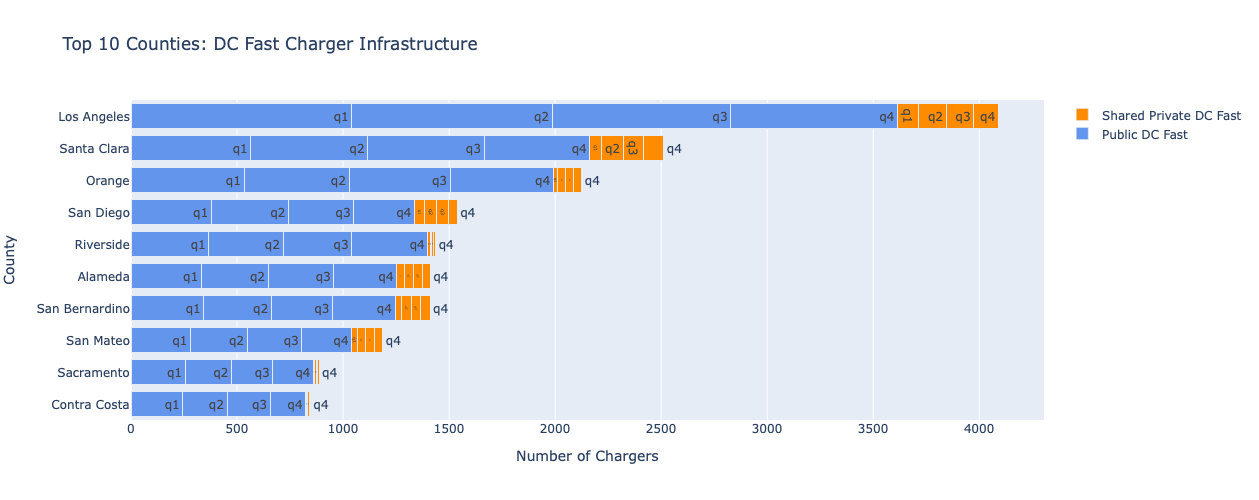

In [378]:
# Top 10 Counties

# Prepare the data
df = mapped21[["county", "public_dc_fast", "shared_private_dc_fast", "total", "quarter", "fips", "county_name"]].copy()
df = df[~df["county"].isin(["Total", "Unknown"])]


#  Identify the Top 10 Counties by combined total
# We sum the columns, find the top 10 unique county names, and convert to a list
top_10_counties = (
    df.groupby("county")[["public_dc_fast", "shared_private_dc_fast"]]
    .sum()
    .sum(axis=1)  # Combine both public and private totals
    .nlargest(10)  # Get the top 10 largest
    .index.tolist()
)

#  Filter original DataFrame to include ONLY those top 10 counties
# This preserves all 4 quarter rows for each of the top 10 counties
df_top10 = df[df["county"].isin(top_10_counties)].copy()

# Re-generate the quarter labels list tailored to the new filtered dataframe length
quarter_labels_top10 = ["q1", "q2", "q3", "q4"] * (len(df_top10) // 4)


# Build the plot using the filtered data
fig = go.Figure()

# Add trace for Public DC Fast Chargers
fig.add_trace(
    go.Bar(
        y=df_top10["county"],
        x=df_top10["public_dc_fast"],
        name="Public DC Fast",
        text=quarter_labels_top10, 
        orientation="h",
        marker=dict(color="cornflowerblue"),
    )
)

# Add trace for Shared Private DC Fast Chargers
fig.add_trace(
    go.Bar(
        y=df_top10["county"],
        x=df_top10["shared_private_dc_fast"],
        name="Shared Private DC Fast",
        text=quarter_labels_top10, 
        orientation="h",
        marker=dict(color="darkorange"),
    )
)

# Clean up layout formatting
fig.update_layout(
    barmode="stack",
    title="Top 10 Counties: DC Fast Charger Infrastructure",
    xaxis_title="Number of Chargers",
    yaxis_title="County",
    yaxis={"categoryorder": "total ascending"},
    height=500,  
)

fig.show()


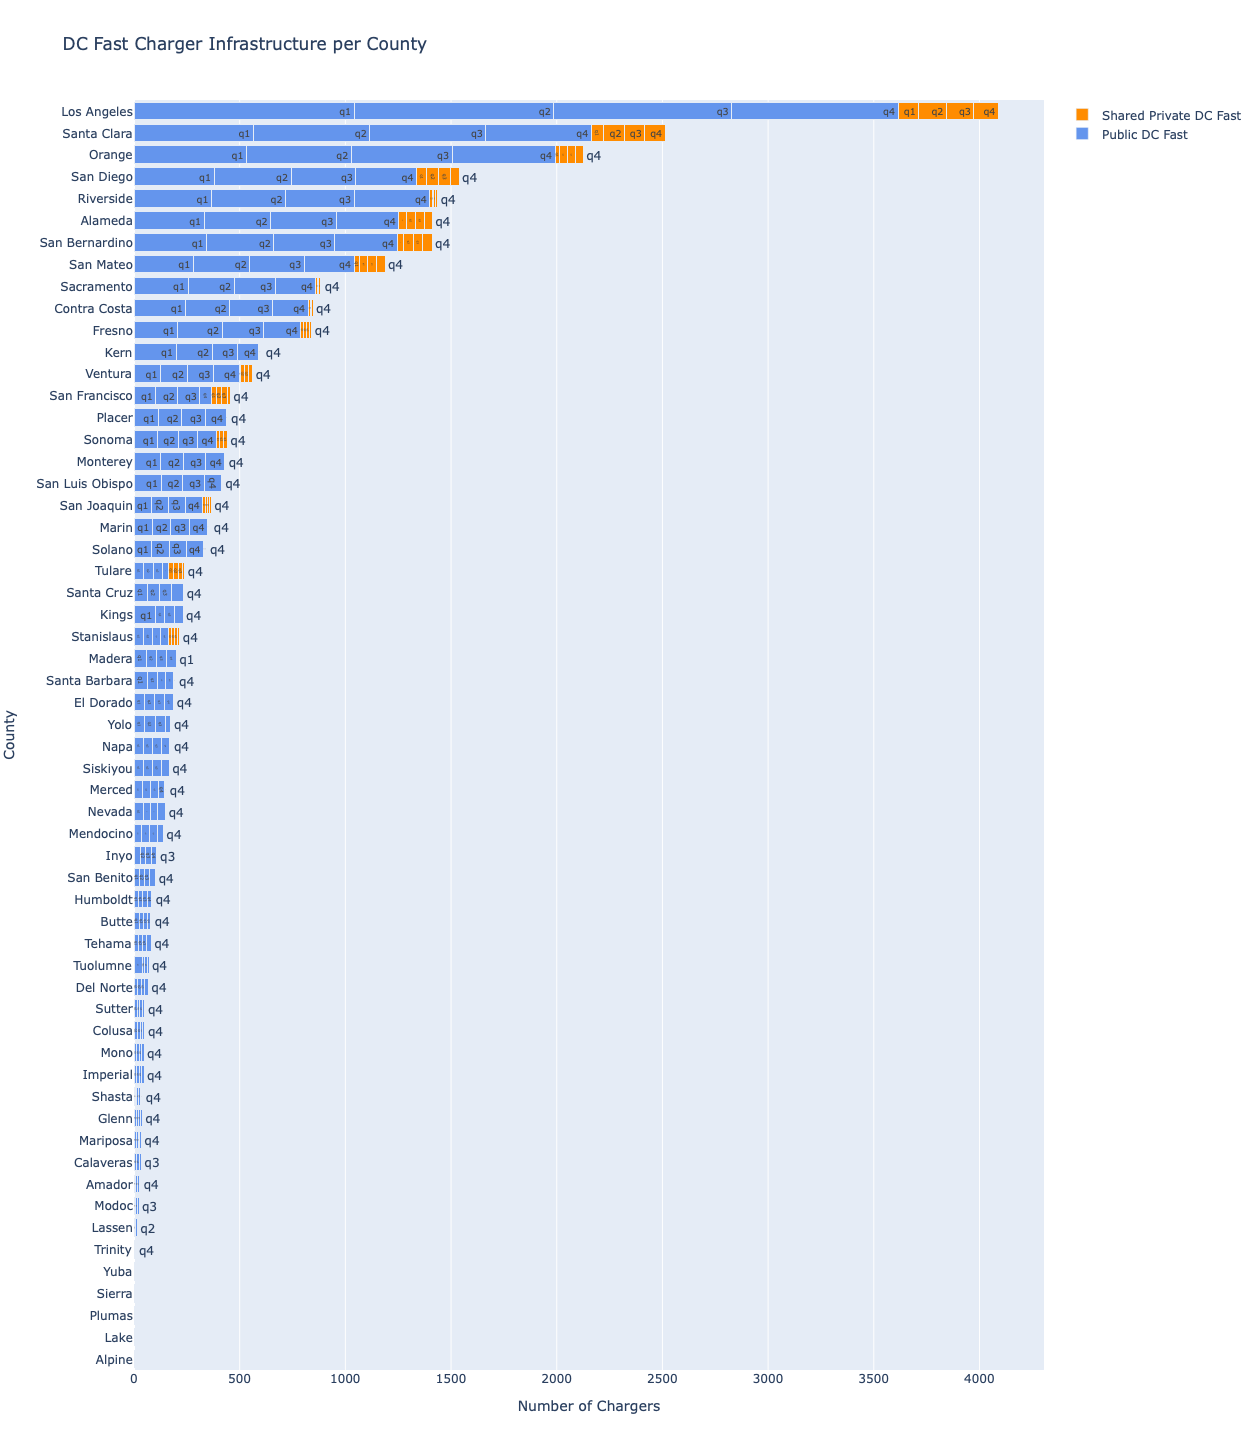

In [380]:
# All counties

fig = go.Figure()
quarter_labels = ["q1", "q2", "q3", "q4"] * (len(df) // 4)

fig.add_trace(
    go.Bar(
        y=df["county"],
        x=df["public_dc_fast"],
        name="Public DC Fast",
        text=quarter_labels, 
        orientation="h",
        marker=dict(color="cornflowerblue"),
    )
)

fig.add_trace(
    go.Bar(
        y=df["county"],
        x=df["shared_private_dc_fast"],
        name="Shared Private DC Fast",
        text=quarter_labels, 
        orientation="h",
        marker=dict(color="darkorange"),
    )
)

# --- CALCULATE DYNAMIC HEIGHT ---
# Giving roughly 25-30 pixels per unique county ensures text & bars aren't squished
num_counties = df["county"].nunique()
calculated_height = max(400, num_counties * 25) 

fig.update_layout(
    barmode="stack",
    title="DC Fast Charger Infrastructure per County",
    xaxis_title="Number of Chargers",
    yaxis_title="County",
    yaxis={"categoryorder": "total ascending"},
    height=calculated_height,  # <--- Forces the chart to stretch vertically
)

fig.show()


Yes — I’d make it a **“DC Fast Growth Race”**:

- **Y-axis:** California counties, dynamically ranked by **DC Fast chargers**.
- **X-axis:** Number of DC Fast chargers.
- **Animation slider:** Q1 → Q2 → Q3 → Q4.
- **Bar color:** `DC Fast share` of the county's total infrastructure — darker = more DC-focused.
- **Hover:** Total chargers + Public DC Fast + Shared/private DC Fast + DC Fast %.
- **Top N:** Show top 15–20 counties to keep the race readable.
- **Key insight:** You simultaneously see **where DC fast infrastructure is concentrated, how much it grows, and whether a county's infrastructure is increasingly fast-charging-oriented.**

This is probably more compelling than the map because it directly exposes **leaders, growth, and charging type** in one visualization.

## SQL Analysis 

### Public Chargers & DC Fast

In [57]:
#!pip install ipython-sql

In [58]:
# connect library
cnn = sqlite3.connect('tutorial.db')

In [59]:
#load
%load_ext sql

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [60]:
#renaming columns for SQL
ev21_sql = ev21.rename(columns={"Public Level 1": "pub_l1", "Shared Private Level 1": "priv_l1", "Public Level 2": "pub_l2", "Shared Private Level 2": "priv_l2", "Public DC Fast": "pub_dc", "Shared Private DC Fast":"priv_dc"})
ev21_sql

,County,pub_l1,priv_l1,pub_l2,priv_l2,pub_dc,priv_dc,Total,Quarter
239,Total,326,109,24880,39201,5404,559,70479,q1
206,Monterey,15,0,231,82,93,1,422,q1
205,Mono,0,0,20,0,12,0,32,q1
204,Modoc,0,0,4,0,0,0,4,q1
203,Merced,10,0,52,37,28,3,130,q1
...,...,...,...,...,...,...,...,...,...
34,San Benito,0,0,12,10,25,0,47,q4
33,Sacramento,69,18,825,639,256,6,1813,q4
32,Riverside,3,1,981,186,367,10,1548,q4
30,Placer,0,1,196,106,115,1,419,q4


In [61]:
%sql sqlite:///tutorial.db
    
ev21.to_sql('ev21', cnn, if_exists='replace')
ev21_sql.to_sql('ev21_sql', cnn, if_exists='replace')


240

In [62]:
%%sql
SELECT * FROM ev21
WHERE County = "Los Angeles"
LIMIT 5;

 * sqlite:///tutorial.db
Done.


index,County,Public Level 1,Shared Private Level 1,Public Level 2,Shared Private Level 2,Public DC Fast,Shared Private DC Fast,Total,Quarter
198,Los Angeles,33,46,6560,11694,787,116,19236,q1
78,Los Angeles,33,147,7087,11954,842,130,20193,q2
138,Los Angeles,33,147,7124,12141,944,131,20520,q3
18,Los Angeles,31,147,7380,12252,1042,98,20950,q4


#### The 5 Counties with the Most EV Chargers in 2021 Q1?

In [63]:
query_1 = """
SELECT county, total, quarter FROM ev21_sql
WHERE quarter = 'q1'
GROUP BY county
ORDER BY total DESC
LIMIT 5
OFFSET 1;

"""
res_1 = pd.read_sql(query_1, cnn)
res_1

#offset 1 to exclude "total row"
#ev21.groupby("County").sum().sort_values("Total", ascending=False).iloc[1:6, :]#[ev21["County"] != 'Total']

,County,Total,Quarter
0,Los Angeles,19236,q1
1,Santa Clara,15406,q1
2,San Diego,6874,q1
3,Orange,5242,q1
4,San Mateo,4070,q1


#### The 5 Counties with the most Public EV Chargers in 2021 Q1?

In [64]:
query_3 = """

SELECT county,  quarter, pub_l1, pub_l2, pub_dc, SUM(pub_l1 + pub_l2 + pub_dc) AS total FROM ev21_sql 
GROUP BY county, quarter
ORDER BY quarter, total DESC
LIMIT 5
OFFSET 1;

"""
res_3 = pd.read_sql(query_3, cnn)
res_3

,County,Quarter,pub_l1,pub_l2,pub_dc,total
0,Los Angeles,q1,33,6560,787,7380
1,Santa Clara,q1,11,3181,499,3691
2,Orange,q1,9,2384,487,2880
3,San Diego,q1,2,1863,287,2152
4,San Mateo,q1,2,1656,235,1893


#### The 5 Counties with the Most DC Fast Chargers in 2021 Q1?

In [65]:
query_2 = """
SELECT county, quarter, pub_dc, priv_dc, SUM(pub_dc + priv_dc) AS DCtotal FROM ev21_sql
GROUP BY county, quarter
ORDER BY quarter, DCtotal DESC
LIMIT 5
OFFSET 1;

"""
res_2 = pd.read_sql(query_2, cnn)
res_2

#offset 1 to exclude "total row"

,County,Quarter,pub_dc,priv_dc,DCtotal
0,Los Angeles,q1,787,116,903
1,Santa Clara,q1,499,96,595
2,Orange,q1,487,38,525
3,Riverside,q1,359,9,368
4,San Bernardino,q1,295,46,341


#### The 10 Counties with the most Public Chargers overall in 2021?

In [66]:
public21 = ev21[["County", "Public Level 1", "Public Level 2", "Public DC Fast"]]#.sum()
public21["Public Total"] = ev21["Public Level 1"] + ev21["Public Level 2"] + ev21["Public DC Fast"]
public21.groupby("County").sum("Public Total").sort_values("Public Total", ascending=False).iloc[1:6, :]

,Public Level 1,Public Level 2,Public DC Fast,Public Total
County,,,,
Los Angeles,130,28151,3615,31896
Santa Clara,23,14508,2164,16695
Orange,31,10288,1992,12311
San Diego,8,7740,1337,9085
San Mateo,8,7931,1041,8980


#### The 5 Counties with the most Public DC Fast Chargers overall in 2021?

In [67]:
percdc = public21.groupby("County").sum("Public Total")
percdc["percentDCFast"] = percdc["Public DC Fast"]/percdc["Public Total"]
percdc.sort_values("percentDCFast", ascending=False).head()
#public21.groupby("County").sum("Public Total").sort_values("percentDCFast", ascending=False).iloc[1:6, :]

,Public Level 1,Public Level 2,Public DC Fast,Public Total,percentDCFast
County,,,,,
Inyo,0,26,107,133,0.804511
Tehama,0,30,82,112,0.732143
Glenn,0,16,40,56,0.714286
San Benito,0,50,103,153,0.673203
Siskiyou,0,84,168,252,0.666667


These counties have the advantage of being rural with more share of the electricity grid, smaller populations, and less EV owners overall.

#### The percent of DCFC Chargers in Counties with the Highest EV Sales?

In [68]:
percg = percdc.reset_index()
percg[percg["County"].isin(temp)]

,County,Public Level 1,Public Level 2,Public DC Fast,Public Total,percentDCFast
0,Alameda,48,6456,1253,7757,0.161532
18,Los Angeles,130,28151,3615,31896,0.113337
29,Orange,31,10288,1992,12311,0.161807
36,San Diego,8,7740,1337,9085,0.147166
42,Santa Clara,23,14508,2164,16695,0.129620


### Basic Analysis - Public DC Fast Charging in CA

 #### Counties with Highest New EV Sales  & Their Percent of DC Fast Chargers in 2021
 - Los Angeles: 11.33%
 - Santa Clara: 12.96%
 - Orange: 16.18%
 - San Diego: 14.7%
 - Alameda: 16.15%


It seems that Los Angeles, Santa Clara, Orange, San Mateo & San Diego have the most public EV chargers overall in 2021. However, these are majorly comprised of Level 2 chargers and they do not accomodate the need for convenience in counties that require fast charging to accomodate their large population size. **DC Fast charging does not make up 20% of charging stations in any of the 5 Counties in CA with the largest number of EV Sales.**

## What about CA County Population sizes ?

### Chargers By Population - adding CA County population data (2021 only)

In [69]:
#need populations
new_path = '/Users/sarasharifzadeh/anaconda3/APROJECTS/projectfiles/ev'
os.chdir(new_path)


pop = pd.read_csv("capop.csv")
pop = pop.rename(columns={"California": "county", "2021": "population"})
pop
pat = "[^\w ]"
pop["county"] = pop["county"].str.replace(pat, "", regex=True)
pop
popmap21 = mapev21.merge(pop, left_on="County", right_on="county", how="inner")
popmap21
popmap21[popmap21["County"]== "Los Angeles"]

popmap21["population"] = popmap21["population"].apply(lambda a: int(a.replace(',', '')))

popmap21
popmap21["chargers_per_100k"] = (popmap21["Total"].astype(int) / popmap21["population"].astype(int))*100000
# min(popmap21["prop per"]), max(popmap21["prop per"])

# popmap21.sort_values("population", ascending=False).head()

popmap21 = popmap21.drop(columns=["county_name", "county"])
popmap21.sort_values("County").head(5)

,County,Public Level 1,Shared Private Level 1,Public Level 2,Shared Private Level 2,Public DC Fast,Shared Private DC Fast,Total,Quarter,fips,population,chargers_per_100k
103,Alameda,6,70,1671,1583,332,35,3697,q4,6001,1643837,224.900644
100,Alameda,14,14,1519,1472,296,38,3353,q1,6001,1643837,203.973995
102,Alameda,14,66,1633,1554,315,43,3625,q3,6001,1643837,220.520648
101,Alameda,14,63,1633,1497,310,43,3560,q2,6001,1643837,216.566484
96,Alpine,0,0,14,1,0,0,15,q1,6003,1235,1214.574899


In [70]:
popmap21.to_sql('popmap21new', cnn, if_exists='replace')

228

### The 5 Counties with the Largest Populations

In [71]:
query_5 = """
SELECT county, population FROM popmap21new
GROUP BY county
ORDER BY population DESC
LIMIT 5
;

"""
res_5 = pd.read_sql(query_5, cnn)
res_5

,County,population
0,Los Angeles,9811842
1,San Diego,3274954
2,Orange,3161005
3,Riverside,2453178
4,San Bernardino,2192882


Note: The data is variable, so I intentionally used non-uniform bins to aid my understanding.

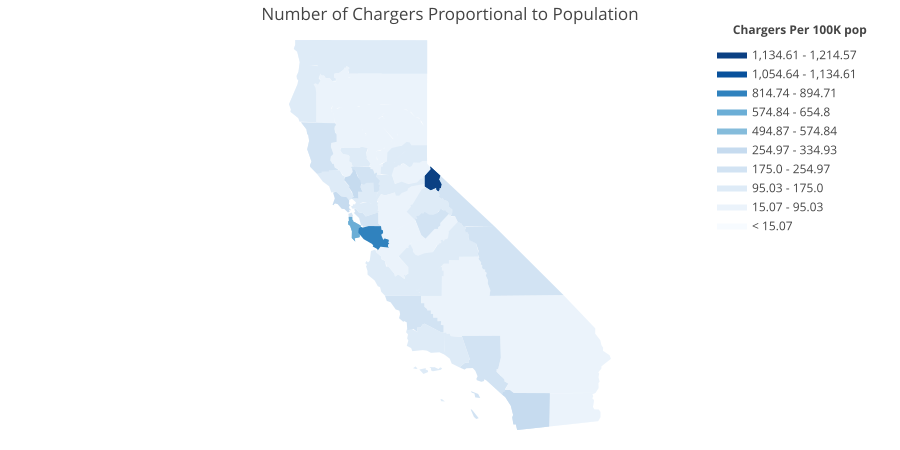

In [72]:
colorscale = ["#f7fbff", "#ebf3fb", "#deebf7", "#d2e3f3", "#c6dbef", "#b3d2e9", "#9ecae1",
    "#85bcdb", "#6baed6", "#57a0ce", "#4292c6", "#3082be", "#2171b5", "#1361a9",
    "#08519c", "#0b4083", "#08306b"
]

values = popmap21['chargers_per_100k'].tolist()
fips = popmap21['fips'].tolist()

#endpts = list(np.mgrid[min(popmap21["prop per"]):max(popmap21["prop per"]):16j])
#np.logspace(np.log10(0.1),np.log10(1.0), 50)

endpts = list(np.mgrid[min(values):max(values):16j])
#endpts = [500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500]

fig = ff.create_choropleth(
    fips=fips, values=values, scope=['CA'],
    binning_endpoints=endpts, 
    colorscale=colorscale,
    show_state_data=False,
    show_hover=True,
    asp = 2.9,
    title_text = 'Number of Chargers Proportional to Population',
    legend_title = 'Chargers Per 100K pop'
)
fig.layout.template = None
fig.show(renderer="svg")

#### The Best Counties for Charging as determined by Proportion of Chargers

In [73]:
query_4 = """
SELECT county, total AS chargers, population, MAX(chargers_per_100k) AS chargers_per_100k FROM popmap21new
GROUP BY county
ORDER BY chargers_per_100k DESC
LIMIT 5
;

"""
res_4 = pd.read_sql(query_4, cnn)
res_4

,County,chargers,population,chargers_per_100k
0,Alpine,15,1235,1214.574899
1,Santa Clara,16498,1886595,874.485515
2,San Mateo,4701,739060,636.078262
3,San Diego,10080,3274954,307.790583
4,Napa,393,136206,288.533545


### Overall Analysis

* **The 5 Counties with the Highest Number of EV Sales are:** Los Angeles, Orange, Santa Clara, San Diego, & Alameda County.

* **The 5 Counties that appear to be the "best" for EV Charging in 2021 as determined by the proportion of chargers against the population of the county are:** Alpine, Santa Clara, San Mateo, San Diego, & Napa County. 

* **The 5 Counties that appear to be the "best" for EV Charging in 2021 as determined by the proportion of DC Fast chargers against the total amount of Public Chargers:** Inyo, Tehama, Glenn, Benito, & Siskiyou County.

Some of these counties are more rural with smaller populations, like Alpine. Other counties like San Mateo & Santa Clara benefit from smaller total square miles. However, despite having a large population, a county like San Diego has a favorable advantage given the balance between the chargers per square mile. 

From above, we saw that despite Los Angeles, Santa Clara, Orange, San Mateo & San Diego taking up the most share of most public EV chargers overall in 2021, **they do not have enough DC Fast Chargers to accomodate the number of vehicles on the road in 2021:**

**Percent share of DC Fast amongst Public Chargers (2021) in CA County's with Highest EV Sales**
 - Los Angeles: 11.33%
 - Santa Clara: 12.96%
 - Orange: 16.18%
 - San Diego: 14.7%
 - Alameda: 16.15%



Ultimately, the public need more access to quick & convient charging as the demand for EV's rise. In order to accomodate growing demand and support urban communities, charging infrastrucure must adopt more DC Fast Chargers. 